
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 600.  Construct portfolios from the 600 stocks in the S&P 600 small cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp600-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AAMI,Acadian Asset Management Inc.,US Stocks:Financials,178.31,132.06,111.98,103.53,56.52,29.07,42.96,15.99,36.38,35.84,36.98,56.52,35.84,1.58
1,AAP,"Advance Auto Parts, Inc.",US Stocks:Consumer Discretionary,5.02,30.72,1.02,3.66,-5.86,-21.32,60.00,37.46,48.14,54.98,50.65,-5.86,54.98,-322.18
2,AAT,American Assets Trust,US Stocks:Real Estate,102.19,95.14,26.13,27.13,9.08,-2.94,19.58,15.33,22.99,25.07,27.77,9.08,25.07,0.36
3,ABCB,Ameris Bancorp,US Stocks:Financials,17.37,21.96,26.49,33.63,30.70,15.34,21.62,11.82,16.38,26.72,31.09,30.70,26.72,1.15
4,ABG,Asbury Automotive Group,US Stocks:Consumer Discretionary,79.60,-8.62,5.81,8.32,2.21,3.61,47.10,26.80,27.05,33.16,35.46,2.21,33.16,0.07
5,ABM,"ABM Industries, Inc.",US Stocks:Industrials,110.43,16.16,3.98,7.57,4.34,3.09,24.42,13.63,26.60,25.40,25.60,4.34,25.40,0.17
6,ABR,Arbor Realty Trust,US Stocks:Financials,-83.85,-56.37,-53.96,-51.17,-24.42,-13.69,34.88,27.50,33.40,32.47,38.05,-24.42,32.47,-792.92
7,ACA,"Arcosa, Inc.",US Stocks:Industrials,142.25,65.29,65.33,63.65,24.36,23.09,3.47,1.92,27.65,29.44,28.89,24.36,29.44,0.83
8,ACAD,Acadia Pharmaceuticals,US Stocks:Healthcare,104.57,7.39,17.32,16.45,-3.56,3.62,24.86,12.55,31.94,51.66,47.91,-3.56,51.66,-183.91
9,ACHC,Acadia Healthcare,US Stocks:Healthcare,-1.69,338.38,26.42,20.54,-28.18,-14.37,72.10,58.60,85.31,63.10,52.58,-28.18,63.10,-1778.16


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
333,MDU,"MDU Resources Group, Inc.",US Stocks:Utilities,-29.64,-1.96,20.72,22.04,20.58,14.30,18.12,12.94,22.96,25.19,23.89,20.58,25.19,0.82
10,ACIW,ACI Worldwide,US Stocks:Technology,206.52,75.88,32.20,35.18,35.05,10.66,37.64,19.59,30.76,33.23,34.53,35.05,33.23,1.05
137,CURB,Curbline Properties Corp.,US Stocks:Real Estate,53.50,72.58,37.00,35.01,37.00,37.00,22.14,14.10,17.46,17.50,17.50,37.00,17.50,2.11
106,CENX,Century Aluminum Company,US Stocks:Materials,-66.47,-16.11,100.99,88.43,69.97,28.62,48.55,23.09,54.07,61.00,69.73,69.97,61.00,1.15
24,AGX,"Argan, Inc.",US Stocks:Industrials,-28.02,161.94,144.65,108.83,149.99,70.50,102.72,54.71,62.84,49.03,42.73,149.99,49.03,3.06
435,PTGX,"Protagonist Therapeutics, Inc.",US Stocks:Healthcare,292.15,187.54,152.03,136.40,92.75,24.25,52.84,23.78,32.62,41.95,72.16,92.75,41.95,2.21
150,DAVE,"Dave, Inc.",US Stocks:Financials,364.25,366.26,71.48,77.82,310.73,3.64,50.27,28.55,74.04,135.04,130.32,310.73,135.04,2.30
50,AROC,"Archrock, Inc.",US Stocks:Energy,-22.68,59.93,54.38,55.48,52.53,40.52,39.70,26.50,38.03,32.13,34.57,52.53,32.13,1.63
432,PSMT,PriceSmart,US Stocks:Consumer Staples,144.28,85.23,81.35,79.70,36.64,19.26,30.58,17.00,23.85,25.23,26.64,36.64,25.23,1.45
296,LAUR,"Laureate Education, Inc.",US Stocks:Consumer Discretionary,118.56,26.36,67.22,66.75,47.75,41.68,31.95,22.61,33.32,24.33,28.77,47.75,24.33,1.96


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,MDU,ACIW,CURB,CENX,AGX,PTGX,DAVE,AROC,PSMT,LAUR,MSGS,Ranked Portfolio
Annual Returns,20.58,35.05,37.00,69.97,149.99,92.75,310.73,52.53,36.64,47.75,28.21,61.64
Std Dev,25.19,33.23,17.50,61.00,49.03,41.95,135.04,32.13,25.23,24.33,22.94,22.48
Sharpe Ratio,0.82,1.05,2.11,1.15,3.06,2.21,2.30,1.63,1.45,1.96,1.23,2.74
Weight,0.13,0.09,0.12,0.07,0.03,0.07,0.06,0.07,0.10,0.08,0.17,1.00
Worst Typical Down Year,-29.80,-31.41,2.00,-52.03,51.93,8.85,40.65,-11.73,-13.82,-0.91,-17.67,16.68
Black Swan,-54.99,-64.64,-15.50,-113.03,2.90,-33.10,-94.39,-43.86,-39.05,-25.24,-40.61,-5.79


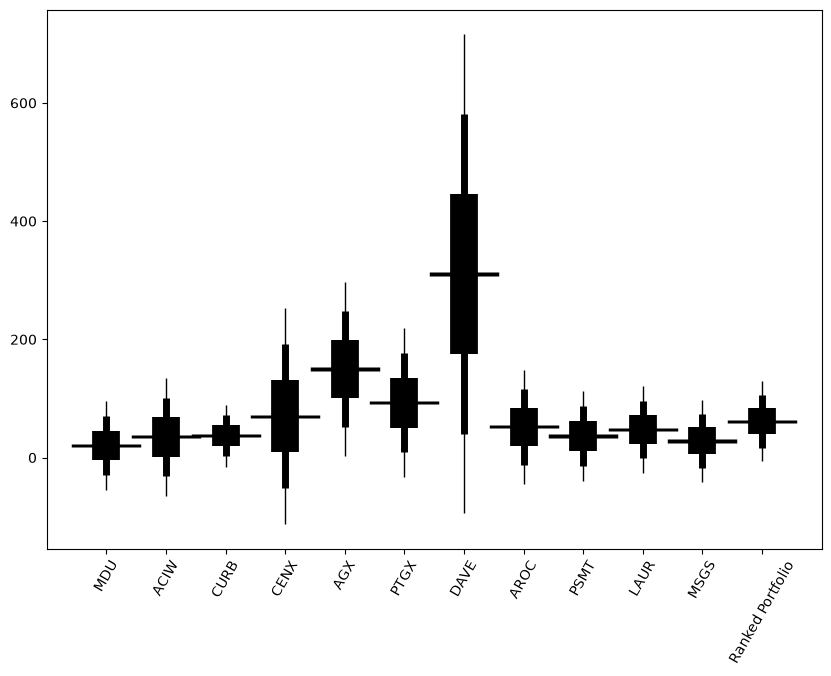

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

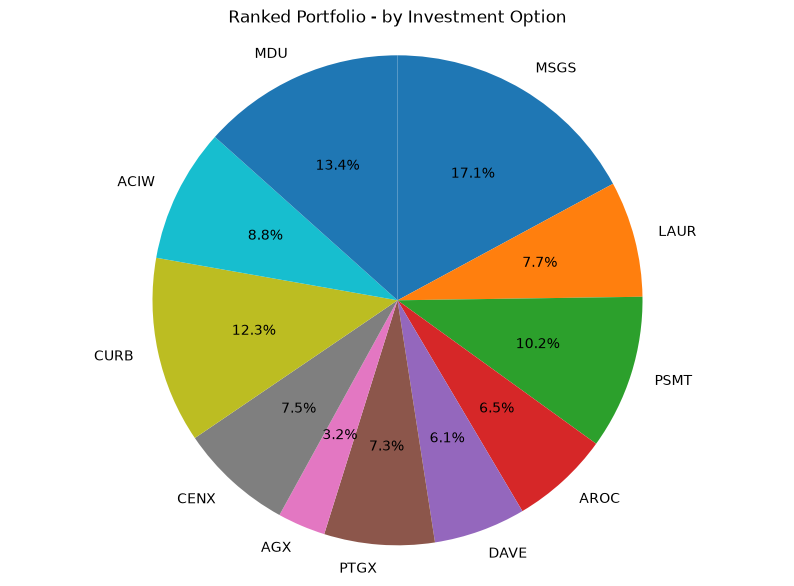

MSGS   0.17
LAUR   0.08
PSMT   0.10
AROC   0.07
DAVE   0.06
PTGX   0.07
AGX    0.03
CENX   0.07
CURB   0.12
ACIW   0.09
MDU    0.13



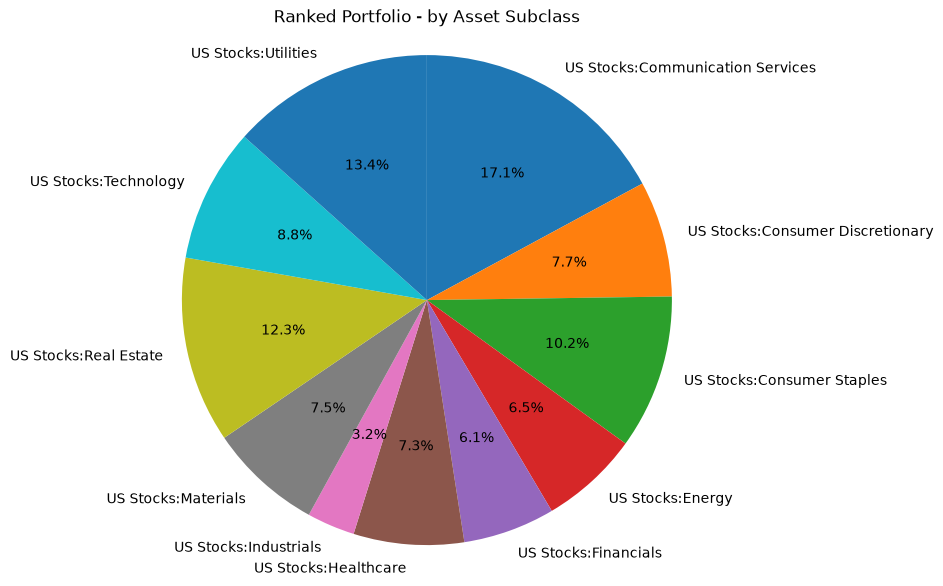

US Stocks:Communication Services   0.17
US Stocks:Consumer Discretionary   0.08
US Stocks:Consumer Staples         0.10
US Stocks:Energy                   0.07
US Stocks:Financials               0.06
US Stocks:Healthcare               0.07
US Stocks:Industrials              0.03
US Stocks:Materials                0.07
US Stocks:Real Estate              0.12
US Stocks:Technology               0.09
US Stocks:Utilities                0.13



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    MDU                            0.1338
    ACIW                           0.0884
    CURB                           0.1228
    CENX                           0.0750
    AGX                            0.0316
    PTGX                           0.0728
    DAVE                           0.0606
    AROC                           0.0653
    PSMT                           0.1019
    LAUR                           0.0766
    MSGS                           0.1711


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).